# 01 · Exploratory data analysis of the M5 dataset

Supports **Section 6.2** of the thesis. The notebook describes the structure of the Walmart (M5) data,
its seasonal and calendar effects, and above all the intermittency of the item-store series, which
motivates the global modelling approach (Chapter 4) and the scaled error measures (Chapter 5).

**Scope.** Every statistic uses the training window only: `d_1`–`d_1913` (2011-01-29 to 2016-04-24).
The validation horizon (`d_1914`–`d_1941`) and the final test horizon (`d_1942`–`d_1969`) are not
looked at, so no modelling decision is informed by evaluation data.

**Outputs**
- figures: `figures/eda/*.png` and `*.pdf`
- tables: `results/eda/*.csv`
- per-series statistics and intermittency classes: `data/processed/series_stats_train.parquet`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import m5_data as m5
from intermittency import ADI_CUTOFF, CV2_CUTOFF, SBC_CLASSES, classify_sbc, demand_stats
from plot_style import (
    ACCENT,
    AXIS,
    CATEGORY_COLORS,
    CONTEXT,
    INK_SECONDARY,
    MUTED,
    NEGATIVE,
    SEQUENTIAL,
    apply_style,
    label_line_end,
    savefig,
)

apply_style()
pd.set_option("display.float_format", "{:,.3f}".format)

RESULTS = ROOT / "results" / "eda"
RESULTS.mkdir(parents=True, exist_ok=True)
m5.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

CATS = ["FOODS", "HOBBIES", "HOUSEHOLD"]
STATES = ["CA", "TX", "WI"]
pct = mtick.PercentFormatter(1.0, decimals=0)
thousands = mtick.FuncFormatter(lambda v, _: "0" if v == 0 else f"{v / 1000:,.0f}k")

## 1. Data structure

In [2]:
sales = m5.load_sales(last_day=m5.TRAIN_END)
calendar = m5.load_calendar()
prices = m5.load_prices()

DAYS = m5.day_cols(1, m5.TRAIN_END)
T = len(DAYS)
cal = calendar.iloc[:T].reset_index(drop=True)  # calendar rows aligned with DAYS
dates = cal["date"]
Y = sales[DAYS].to_numpy()  # (30,490 series x 1,913 days), int16

print(f"sales    : {len(sales):,} series x {T:,} days ({sales.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory)")
print(f"calendar : {len(calendar):,} days, {calendar.date.min():%Y-%m-%d} to {calendar.date.max():%Y-%m-%d}")
print(f"training : {dates.iloc[0]:%Y-%m-%d} to {dates.iloc[-1]:%Y-%m-%d}")
print(f"prices   : {len(prices):,} item-store-week rows")
print(f"zeros    : {(Y == 0).mean():.1%} of all item-store-day cells")

sales    : 30,490 series x 1,913 days (119 MB in memory)
calendar : 1,969 days, 2011-01-29 to 2016-06-19
training : 2011-01-29 to 2016-04-24
prices   : 6,841,121 item-store-week rows
zeros    : 68.2% of all item-store-day cells


In [3]:
level_names = {
    1: "Total", 2: "State", 3: "Store", 4: "Category", 5: "Department", 6: "State × Category",
    7: "State × Department", 8: "Store × Category", 9: "Store × Department", 10: "Item",
    11: "Item × State", 12: "Item × Store",
}
hierarchy = pd.DataFrame(
    {
        "aggregation": [level_names[lvl] for lvl in m5.LEVELS],
        "n_series": [1 if not cols else len(sales[cols].drop_duplicates()) for cols in m5.LEVELS.values()],
    },
    index=pd.Index(list(m5.LEVELS), name="level"),
)
hierarchy.to_csv(RESULTS / "hierarchy_levels.csv")
print(f"Total number of series across the 12 levels: {hierarchy.n_series.sum():,}")
hierarchy

Total number of series across the 12 levels: 42,840


,aggregation,n_series
level,,
1,Total,1
2,State,3
3,Store,10
4,Category,3
5,Department,7
6,State × Category,9
7,State × Department,21
8,Store × Category,30
9,Store × Department,70


In [4]:
assortment = (
    sales.groupby(["cat_id", "dept_id"], observed=True).agg(items=("item_id", "nunique"), series=("id", "size"))
    .reset_index().astype({"cat_id": str, "dept_id": str})
)
assortment.loc[len(assortment)] = ["All", "", sales.item_id.nunique(), len(sales)]
assortment.to_csv(RESULTS / "assortment.csv", index=False)
assortment

,cat_id,dept_id,items,series
0,HOBBIES,HOBBIES_1,416,4160
1,HOBBIES,HOBBIES_2,149,1490
2,HOUSEHOLD,HOUSEHOLD_1,532,5320
3,HOUSEHOLD,HOUSEHOLD_2,515,5150
4,FOODS,FOODS_1,216,2160
5,FOODS,FOODS_2,398,3980
6,FOODS,FOODS_3,823,8230
7,All,,3049,30490


## 2. Product introductions and the active period

Many series start with a run of zeros because the product was not yet on sale. These zeros are not
demand observations, so all intermittency statistics below are computed from each series' **first
sale** onwards. Christmas Day (stores closed, zero sales everywhere) is also excluded from the
demand statistics.

In [5]:
xmas = (dates.dt.month.eq(12) & dates.dt.day.eq(25)).to_numpy()
open_days = np.flatnonzero(~xmas)  # positions of the days the stores were open
print("Christmas days in the training window:", ", ".join(dates[xmas].dt.strftime("%Y-%m-%d")))
print(f"Total units sold on those days: {Y[:, xmas].sum():,}")

stats = demand_stats(Y[:, open_days])
fs = stats["first_sale"].to_numpy()
stats["first_sale"] = np.where(np.isnan(fs), np.nan, open_days[np.nan_to_num(fs, nan=1).astype(int) - 1] + 1)

print(f"Series without any sale in the training window: {stats.first_sale.isna().sum():,}")
print(f"Series whose first sale is after d_1: {(stats.first_sale > 1).mean():.1%}")
leading_zeros = (np.arange(T)[None, :] < (np.nan_to_num(stats.first_sale.to_numpy(), nan=T + 1)[:, None] - 1)).sum()
print(f"Leading (pre-introduction) zeros: {leading_zeros / (Y == 0).sum():.1%} of all zero cells")

Christmas days in the training window: 2011-12-25, 2012-12-25, 2013-12-25, 2014-12-25, 2015-12-25
Total units sold on those days: 78


Series without any sale in the training window: 0
Series whose first sale is after d_1: 77.1%


Leading (pre-introduction) zeros: 31.1% of all zero cells


Median delay between first recorded price and first sale: 2 days (90th percentile 6 days)


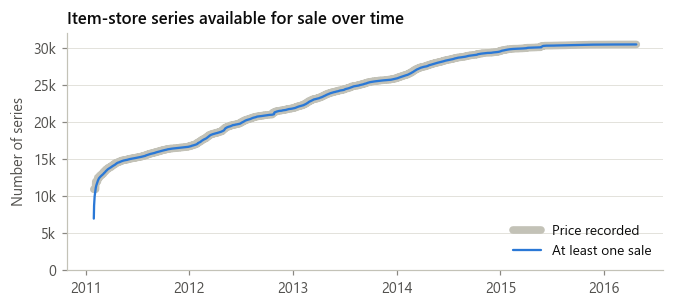

In [6]:
# First week with a recorded price, converted to its first day
first_day_of_week = cal.groupby("wm_yr_wk")["d_num"].min()
first_price_week = prices.groupby(["store_id", "item_id"], observed=True)["wm_yr_wk"].min().rename("first_price_week")
keys = sales[["item_id", "store_id"]].astype(str)
fpw = first_price_week.reset_index().astype({"store_id": str, "item_id": str})
stats["first_price_day"] = keys.merge(fpw, on=["item_id", "store_id"], how="left")["first_price_week"].map(first_day_of_week).to_numpy()

delay = stats.first_sale - stats.first_price_day
print(f"Median delay between first recorded price and first sale: {delay.median():.0f} days "
      f"(90th percentile {delay.quantile(0.9):.0f} days)")


def cumulative_count(first_day):
    counts = np.bincount(first_day.dropna().astype(int), minlength=T + 1)[1 : T + 1]
    return counts.cumsum()


fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(dates, cumulative_count(stats.first_price_day), color=CONTEXT, lw=5, label="Price recorded")
ax.plot(dates, cumulative_count(stats.first_sale), color=ACCENT, label="At least one sale")
ax.set_title("Item-store series available for sale over time")
ax.set_ylabel("Number of series")
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(0, len(sales) * 1.05)
ax.legend(loc="lower right")
savefig(fig, "series_introductions")
plt.show()

## 3. Aggregate sales, trend and calendar effects

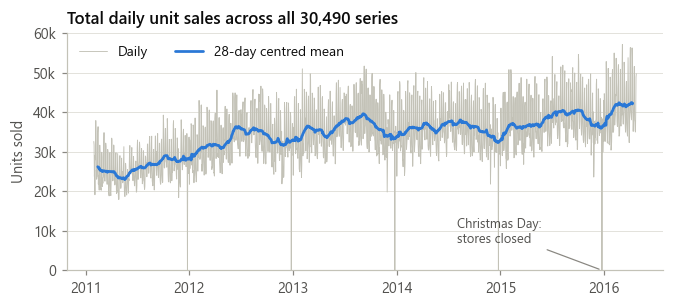

In [7]:
total = pd.Series(Y.sum(axis=0), index=dates, name="units")
closed = total[xmas]

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(total.index, total, color=CONTEXT, lw=0.6, label="Daily")
ax.plot(total.index, total.rolling(28, center=True).mean(), color=ACCENT, lw=1.8, label="28-day centred mean")
ax.annotate("Christmas Day:\nstores closed", xy=(closed.index[-1], closed.iloc[-1]), xytext=(-95, 18),
            textcoords="offset points", color=INK_SECONDARY, fontsize=8.5,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.set_title("Total daily unit sales across all 30,490 series")
ax.set_ylabel("Units sold")
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(0)
ax.legend(loc="upper left", ncols=2)
savefig(fig, "total_sales")
plt.show()

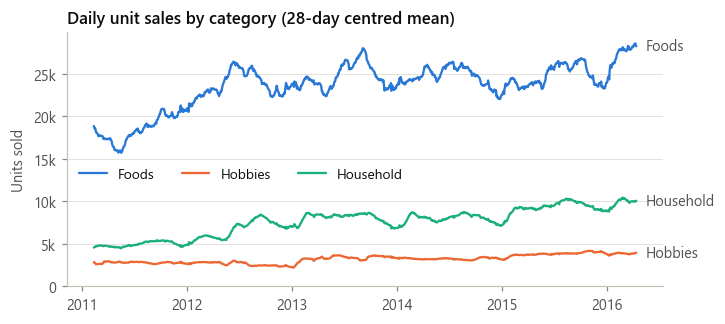

Mean daily units, 2012 vs 2015 (growth):
cat_id
HOBBIES      +45.2%
HOUSEHOLD    +39.5%
FOODS         +4.4%


In [8]:
cat_daily = m5.aggregate(sales, 4, DAYS).T
cat_daily.index = dates
cat_daily.columns = cat_daily.columns.astype(str)

fig, ax = plt.subplots(figsize=(7, 3))
for c in CATS:
    r = cat_daily[c].rolling(28, center=True).mean().dropna()
    ax.plot(r.index, r, color=CATEGORY_COLORS[c], label=c.title())
    label_line_end(ax, r.index[-1], r.iloc[-1], c.title())
ax.set_title("Daily unit sales by category (28-day centred mean)")
ax.set_ylabel("Units sold")
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(0)
ax.legend(loc="center left", bbox_to_anchor=(0, 0.44), ncols=3)
savefig(fig, "sales_by_category")
plt.show()

growth = cat_daily.groupby(dates.dt.year.values).mean().loc[[2012, 2015]]
print("Mean daily units, 2012 vs 2015 (growth):")
print((growth.loc[2015] / growth.loc[2012] - 1).map("{:+.1%}".format).to_string())

**Weekly and yearly seasonality.** The weekday profile is the ratio of daily sales to the centred
7-day mean (so trend and yearly effects cancel); the month profile is the ratio of the monthly mean to
the mean of the same calendar year, averaged over the full years 2012–2015.

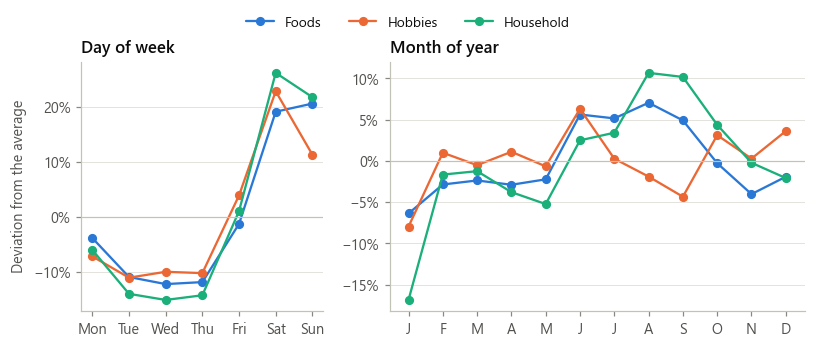

cat_id,HOBBIES,HOUSEHOLD,FOODS
Monday,-7.2%,-6.0%,-3.8%
Tuesday,-11.0%,-14.0%,-10.9%
Wednesday,-10.0%,-15.1%,-12.2%
Thursday,-10.2%,-14.2%,-11.8%
Friday,+3.9%,+1.1%,-1.3%
Saturday,+22.9%,+26.2%,+19.1%
Sunday,+11.3%,+21.8%,+20.6%


In [9]:
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
cd = cat_daily.copy()
cd.iloc[xmas] = np.nan
weekday_ratio = cd / cd.rolling(7, center=True, min_periods=7).mean()
weekday_profile = weekday_ratio.groupby(cal["weekday"].astype(str).values).mean().loc[WEEKDAYS] - 1

years, months = dates.dt.year.to_numpy(), dates.dt.month.to_numpy()
full_years = (years >= 2012) & (years <= 2015)
cdf = cd[full_years]
month_profile = (cdf / cdf.groupby(years[full_years]).transform("mean")).groupby(months[full_years]).mean() - 1

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3), gridspec_kw={"width_ratios": [7, 12]})
for c in CATS:
    axes[0].plot(range(7), weekday_profile[c], marker="o", color=CATEGORY_COLORS[c], label=c.title())
    axes[1].plot(range(1, 13), month_profile[c], marker="o", color=CATEGORY_COLORS[c])
axes[0].set_xticks(range(7), [d[:3] for d in WEEKDAYS])
axes[1].set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
axes[0].set_title("Day of week")
axes[1].set_title("Month of year")
axes[0].set_ylabel("Deviation from the average")
for ax in axes:
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.yaxis.set_major_formatter(pct)
fig.legend(loc="upper center", ncols=3, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
savefig(fig, "seasonality_profiles")
plt.show()

seasonality = pd.concat({"weekday": weekday_profile, "month": month_profile})
seasonality.to_csv(RESULTS / "seasonality_profiles.csv")
weekday_profile.style.format("{:+.1%}")

**SNAP days.** SNAP (food-stamp) benefits are paid on 10 fixed days per month, which differ by state.
The uplift is the ratio of average sales on SNAP days to non-SNAP days, after dividing each day by its
calendar-month mean so that monthly level changes do not confound the comparison.

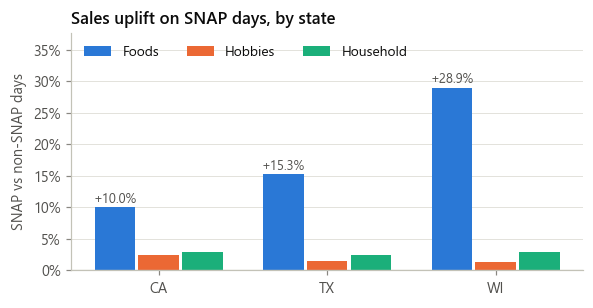

category,FOODS,HOBBIES,HOUSEHOLD
state,,,
CA,+10.0%,+2.4%,+2.9%
TX,+15.3%,+1.4%,+2.4%
WI,+28.9%,+1.3%,+2.9%


In [10]:
st_cat = m5.aggregate(sales, 6, DAYS)
year_month = dates.dt.to_period("M").to_numpy()
rows = []
for (state, cat), row in st_cat.iterrows():
    s = pd.Series(row.to_numpy(dtype=float), index=dates)
    s.iloc[xmas] = np.nan
    rel = s / s.groupby(year_month).transform("mean")
    snap = cal[f"snap_{state}"].to_numpy() == 1
    rows.append({"state": state, "category": cat, "uplift": rel[snap].mean() / rel[~snap].mean() - 1})
snap_effect = pd.DataFrame(rows).pivot(index="state", columns="category", values="uplift").loc[STATES, CATS]
snap_effect.to_csv(RESULTS / "snap_effect.csv")

fig, ax = plt.subplots(figsize=(6, 2.8))
width = 0.24
for i, c in enumerate(CATS):
    x = np.arange(len(STATES)) + (i - 1) * (width + 0.02)
    ax.bar(x, snap_effect[c], width=width, color=CATEGORY_COLORS[c], label=c.title())
    if c == "FOODS":
        for xi, v in zip(x, snap_effect[c]):
            ax.annotate(f"{v:+.1%}", (xi, v), xytext=(0, 3), textcoords="offset points", ha="center", color=INK_SECONDARY, fontsize=8.5)
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_xticks(range(len(STATES)), STATES)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, snap_effect.to_numpy().max() * 1.3)
ax.set_title("Sales uplift on SNAP days, by state")
ax.set_ylabel("SNAP vs non-SNAP days")
ax.legend(loc="upper left", ncols=3)
savefig(fig, "snap_effect")
plt.show()
snap_effect.style.format("{:+.1%}")

**Events.** For each event day the effect is total sales relative to the same weekday one and two weeks
before and after (excluding Christmas Day from the reference days), averaged over all years.
Christmas itself is left out of the chart: it is a store closure, not a demand effect.

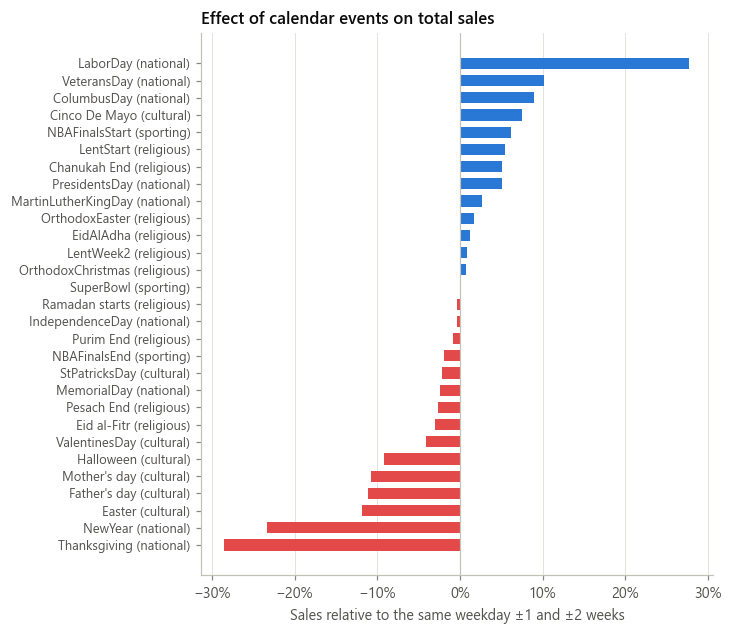

In [11]:
S = total.to_numpy(dtype=float)
ev_name, ev_type = cal["event_name_1"], cal["event_type_1"]
rows = []
for t in np.flatnonzero(ev_name.notna().to_numpy()):
    ref = [t + k for k in (-14, -7, 7, 14) if 0 <= t + k < T and not xmas[t + k]]
    rows.append({"event": ev_name.iloc[t], "type": ev_type.iloc[t], "date": dates.iloc[t], "effect": S[t] / S[ref].mean() - 1})
events = pd.DataFrame(rows)
event_effect = (
    events.groupby(["event", "type"], observed=True)["effect"].agg(effect="mean", occurrences="size")
    .reset_index().sort_values("effect")
)
event_effect.to_csv(RESULTS / "event_effect.csv", index=False)

plot_ev = event_effect[event_effect.event != "Christmas"]
fig, ax = plt.subplots(figsize=(6, 6.4))
ax.barh(np.arange(len(plot_ev)), plot_ev.effect, height=0.65,
        color=np.where(plot_ev.effect >= 0, ACCENT, NEGATIVE))
ax.set_yticks(np.arange(len(plot_ev)), [f"{e} ({t.lower()})" for e, t in zip(plot_ev["event"], plot_ev["type"])], fontsize=8.5)
ax.axvline(0, color=AXIS, lw=0.8)
ax.xaxis.set_major_formatter(pct)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_title("Effect of calendar events on total sales")
ax.set_xlabel("Sales relative to the same weekday ±1 and ±2 weeks")
savefig(fig, "event_effect")
plt.show()

## 4. Autocorrelation: aggregate versus item level

Autocorrelation is computed on the last two years of the training window (728 days), with Christmas
Day replaced by the mean of the same weekday one week before and after. For the item-store level the
chart shows the median and the interquartile range over all series that were already on sale at the
start of that window.

Item-store series used: 27,698


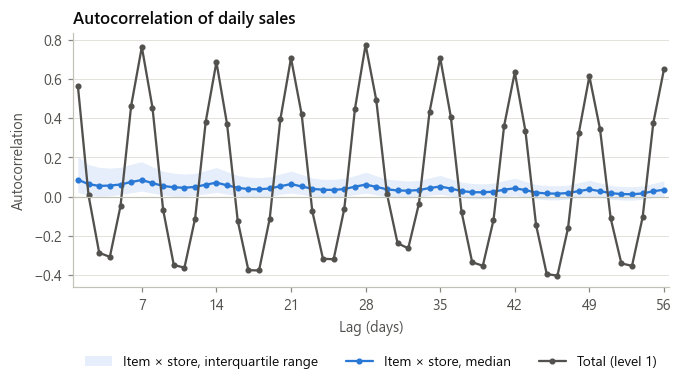

,total,item_median,item_q25,item_q75
lag,,,,
1,0.565,0.087,0.021,0.205
7,0.764,0.085,0.028,0.178
14,0.687,0.071,0.021,0.149
28,0.776,0.061,0.018,0.124


In [12]:
def acf(y: np.ndarray, max_lag: int) -> np.ndarray:
    """Sample autocorrelation of each row of y for lags 1..max_lag."""
    yc = y - y.mean(axis=1, keepdims=True)
    denom = np.square(yc).sum(axis=1)
    return np.stack([(yc[:, k:] * yc[:, :-k]).sum(axis=1) / denom for k in range(1, max_lag + 1)], axis=1)


MAX_LAG = 56
window = np.arange(T - 728, T)
Yw = Y[:, window].astype(float)
for t in np.flatnonzero(xmas[window]):
    Yw[:, t] = (Yw[:, t - 7] + Yw[:, t + 7]) / 2

acf_total = acf(Yw.sum(axis=0, keepdims=True), MAX_LAG)[0]
eligible = (stats.first_sale.to_numpy() <= window[0] + 1) & (Yw.std(axis=1) > 0)
acf_items = acf(Yw[eligible], MAX_LAG)
q25, q50, q75 = np.percentile(acf_items, [25, 50, 75], axis=0)
lags = np.arange(1, MAX_LAG + 1)
print(f"Item-store series used: {eligible.sum():,}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.fill_between(lags, q25, q75, color=ACCENT, alpha=0.12, lw=0, label="Item × store, interquartile range")
ax.plot(lags, q50, color=ACCENT, marker="o", ms=3, label="Item × store, median")
ax.plot(lags, acf_total, color=INK_SECONDARY, marker="o", ms=3, label="Total (level 1)")
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_xticks(range(7, MAX_LAG + 1, 7))
ax.set_xlim(0.5, MAX_LAG + 0.5)
ax.set_title("Autocorrelation of daily sales")
ax.set_xlabel("Lag (days)")
ax.set_ylabel("Autocorrelation")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncols=3)
savefig(fig, "acf_total_vs_items")
plt.show()

acf_table = pd.DataFrame({"total": acf_total, "item_median": q50, "item_q25": q25, "item_q75": q75}, index=pd.Index(lags, name="lag"))
acf_table.to_csv(RESULTS / "acf.csv")
acf_table.loc[[1, 7, 14, 28]]

## 5. Intermittency at the item-store level

Statistics per series over its active period (first sale to `d_1913`, Christmas excluded):
- **zero share**: fraction of days without a sale;
- **ADI** (average inter-demand interval): active days divided by days with a sale;
- **CV²**: squared coefficient of variation of the non-zero sale sizes.

The Syntetos–Boylan–Croston classification uses the cut-offs ADI = 1.32 and CV² = 0.49.

In [13]:
stats["cat_id"] = sales["cat_id"].astype(str).to_numpy()
stats["sbc_class"] = classify_sbc(stats.adi, stats.cv2)

by_cat = stats.groupby("cat_id")["zero_share"]
zero_summary = pd.concat([by_cat.describe(), stats["zero_share"].describe().to_frame("All").T])
zero_summary["share_over_50pct_zero"] = pd.concat(
    [by_cat.apply(lambda z: (z > 0.5).mean()), pd.Series({"All": (stats.zero_share > 0.5).mean()})]
)
zero_summary.to_csv(RESULTS / "zero_share_by_category.csv")
zero_summary

,count,mean,std,min,25%,50%,75%,max,share_over_50pct_zero
FOODS,"14,370.000",0.522,0.223,0.000,0.353,0.539,0.702,0.987,0.557
HOBBIES,"5,650.000",0.722,0.191,0.014,0.607,0.778,0.875,0.987,0.849
HOUSEHOLD,"10,470.000",0.641,0.234,0.009,0.484,0.696,0.833,0.993,0.734
All,"30,490.000",0.600,0.235,0.000,0.431,0.633,0.796,0.993,0.672


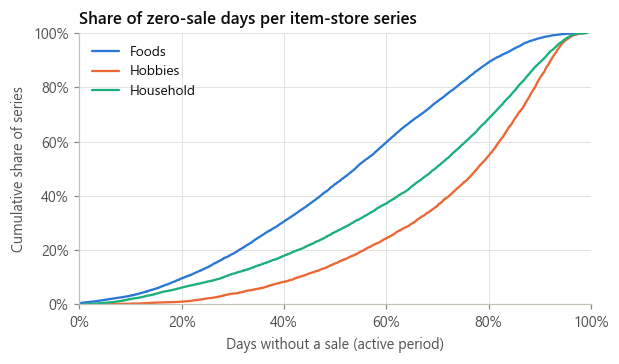

In [14]:
fig, ax = plt.subplots(figsize=(6, 3.2))
for c in CATS:
    z = np.sort(stats.loc[stats.cat_id == c, "zero_share"].dropna().to_numpy())
    ax.plot(z, np.arange(1, len(z) + 1) / len(z), color=CATEGORY_COLORS[c], label=c.title())
ax.xaxis.set_major_formatter(pct)
ax.yaxis.set_major_formatter(pct)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(axis="x", visible=True)
ax.set_title("Share of zero-sale days per item-store series")
ax.set_xlabel("Days without a sale (active period)")
ax.set_ylabel("Cumulative share of series")
ax.legend(loc="upper left")
savefig(fig, "zero_share_ecdf")
plt.show()

Series whose non-zero sales are (almost) always the same size, typically one unit, have CV² close to
zero; on the log scale they are drawn at CV² = 0.01.

Series with CV² < 0.01 (drawn at 0.01): 25


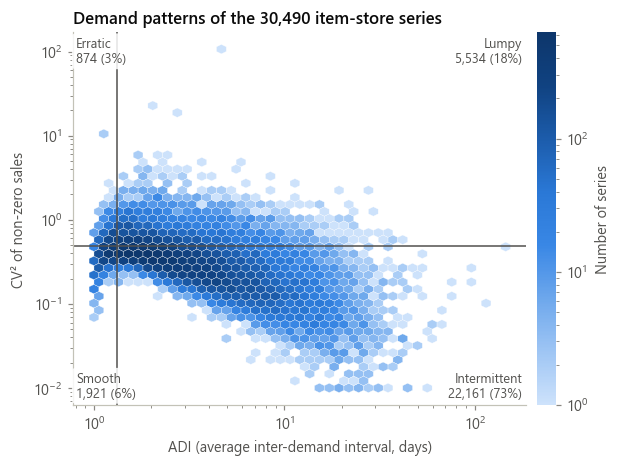

In [15]:
sbc = stats.dropna(subset=["adi", "cv2"])
print(f"Series with CV² < 0.01 (drawn at 0.01): {(sbc.cv2 < 0.01).sum():,}")
counts = sbc["sbc_class"].value_counts().reindex(SBC_CLASSES)

fig, ax = plt.subplots(figsize=(6.4, 4.4))
hb = ax.hexbin(sbc.adi, sbc.cv2.clip(lower=0.01), xscale="log", yscale="log", gridsize=42, cmap=SEQUENTIAL,
               mincnt=1, bins="log", linewidths=0.2, edgecolors="white")
ax.axvline(ADI_CUTOFF, color=INK_SECONDARY, lw=1)
ax.axhline(CV2_CUTOFF, color=INK_SECONDARY, lw=1)
ax.grid(False)
x_lo, x_hi = ax.get_xlim()
y_lo, y_hi = ax.get_ylim()
quadrants = {"smooth": (x_lo * 1.03, y_lo * 1.15, "left", "bottom"), "erratic": (x_lo * 1.03, y_hi / 1.15, "left", "top"),
             "intermittent": (x_hi / 1.05, y_lo * 1.15, "right", "bottom"), "lumpy": (x_hi / 1.05, y_hi / 1.15, "right", "top")}
for cls, (x, y, ha, va) in quadrants.items():
    ax.text(x, y, f"{cls.capitalize()}\n{counts[cls]:,} ({counts[cls] / counts.sum():.0%})", ha=ha, va=va,
            fontsize=8.5, color=INK_SECONDARY, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="none", alpha=0.85))
cb = fig.colorbar(hb, ax=ax, pad=0.02)
cb.set_label("Number of series", color=INK_SECONDARY)
cb.outline.set_visible(False)
ax.set_title("Demand patterns of the 30,490 item-store series")
ax.set_xlabel("ADI (average inter-demand interval, days)")
ax.set_ylabel("CV² of non-zero sales")
savefig(fig, "adi_cv2_classification")
plt.show()

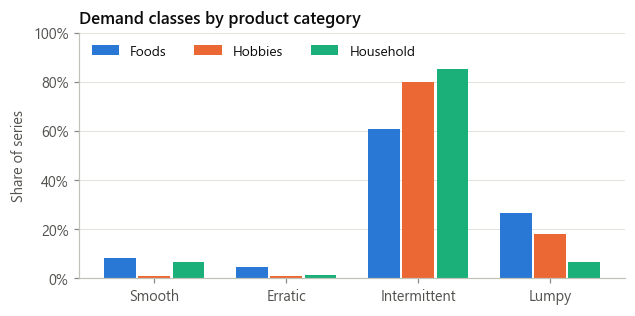

sbc_class,smooth,erratic,intermittent,lumpy
cat_id,,,,
FOODS,8.3%,4.5%,60.6%,26.5%
HOBBIES,0.8%,1.0%,79.9%,18.2%
HOUSEHOLD,6.4%,1.5%,85.4%,6.6%
All,6.3%,2.9%,72.7%,18.2%


In [16]:
sbc_by_cat = pd.crosstab(stats.cat_id, stats.sbc_class, normalize="index").reindex(columns=SBC_CLASSES)
sbc_by_cat.loc["All"] = stats.sbc_class.value_counts(normalize=True).reindex(SBC_CLASSES)
sbc_counts = pd.crosstab(stats.cat_id, stats.sbc_class, margins=True, margins_name="All").reindex(columns=[*SBC_CLASSES, "All"])
sbc_counts.to_csv(RESULTS / "sbc_classes_counts.csv")
sbc_by_cat.to_csv(RESULTS / "sbc_classes_share.csv")

fig, ax = plt.subplots(figsize=(6.4, 2.9))
width = 0.24
for i, c in enumerate(CATS):
    x = np.arange(len(SBC_CLASSES)) + (i - 1) * (width + 0.02)
    ax.bar(x, sbc_by_cat.loc[c], width=width, color=CATEGORY_COLORS[c], label=c.title())
ax.set_xticks(range(len(SBC_CLASSES)), [s.capitalize() for s in SBC_CLASSES])
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 1)
ax.set_title("Demand classes by product category")
ax.set_ylabel("Share of series")
ax.legend(loc="upper left", ncols=3)
savefig(fig, "sbc_classes_by_category")
plt.show()
sbc_by_cat.style.format("{:.1%}")

## 6. Intermittency across the hierarchy

The same statistics for every aggregation level. Intermittency is a property of the bottom of the
hierarchy: it disappears quickly as series are summed, which matters for the WRMSSE evaluation across
levels (Section 7.4).

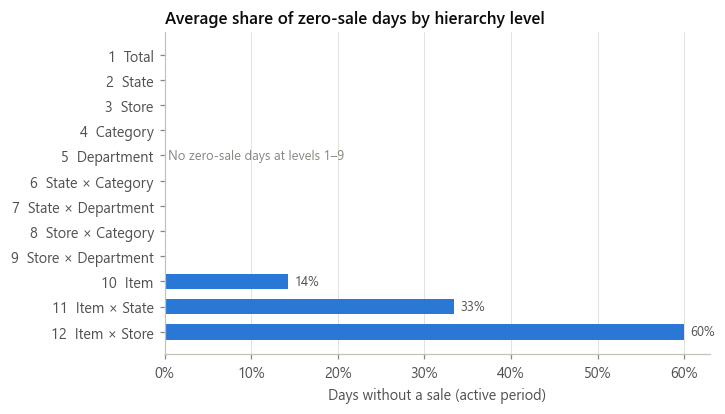

,aggregation,n_series,mean_zero_share,median_adi,share_intermittent_or_lumpy
level,,,,,
1,Total,1,0.000,1.000,0.000
2,State,3,0.000,1.000,0.000
3,Store,10,0.000,1.000,0.000
4,Category,3,0.000,1.000,0.000
5,Department,7,0.000,1.000,0.000
6,State × Category,9,0.000,1.000,0.000
7,State × Department,21,0.000,1.000,0.000
8,Store × Category,30,0.000,1.000,0.000
9,Store × Department,70,0.000,1.000,0.000


In [17]:
level_rows = []
for lvl in m5.LEVELS:
    st = stats if lvl == 12 else demand_stats(m5.aggregate(sales, lvl, DAYS).to_numpy()[:, open_days])
    cls = classify_sbc(st.adi, st.cv2)
    level_rows.append(
        {
            "level": lvl,
            "aggregation": level_names[lvl],
            "n_series": len(st),
            "mean_zero_share": st.zero_share.mean(),
            "median_adi": st.adi.median(),
            "share_intermittent_or_lumpy": pd.Series(cls).isin(["intermittent", "lumpy"]).mean(),
        }
    )
by_level = pd.DataFrame(level_rows).set_index("level")
by_level.to_csv(RESULTS / "intermittency_by_level.csv")

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ypos = np.arange(len(by_level))[::-1]
ax.barh(ypos, by_level.mean_zero_share, height=0.62, color=ACCENT)
ax.set_yticks(ypos, [f"{lvl}  {name}" for lvl, name in zip(by_level.index, by_level.aggregation)])
for y, v in zip(ypos, by_level.mean_zero_share):
    if v >= 0.005:
        ax.annotate(f"{v:.0%}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK_SECONDARY, fontsize=8.5)
ax.annotate("No zero-sale days at levels 1–9", (0.004, ypos[4]), va="center", color=MUTED, fontsize=8.5)
ax.xaxis.set_major_formatter(pct)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_title("Average share of zero-sale days by hierarchy level")
ax.set_xlabel("Days without a sale (active period)")
savefig(fig, "zero_share_by_level")
plt.show()
by_level

## 7. Concentration of volume and revenue

The WRMSSE weights each series by its revenue in the last 28 days of the training data
(`d_1886`–`d_1913`). The concentration curves show how much of the units and revenue a small share of
series accounts for.

Top 10% of series: 52.2% of units, 48.8% of revenue
Top 20% of series: 68.4% of units, 65.1% of revenue
Series with no sale in the last 28 days (zero WRMSSE weight at level 12): 5.2%


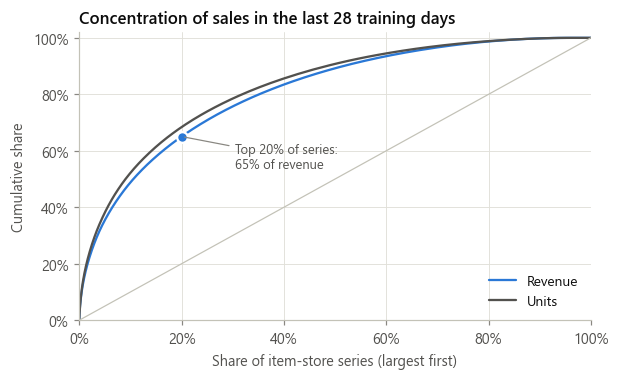

In [18]:
last28 = m5.day_cols(m5.TRAIN_END - 27, m5.TRAIN_END)
week_of_day = cal.set_index("d")["wm_yr_wk"]
recent = sales[["item_id", "store_id", *last28]].astype({"item_id": str, "store_id": str})
recent = recent.reset_index(names="row").melt(["row", "item_id", "store_id"], var_name="d", value_name="units")
recent["wm_yr_wk"] = recent["d"].map(week_of_day)
recent_prices = prices[prices.wm_yr_wk.isin(recent["wm_yr_wk"].unique())].astype({"item_id": str, "store_id": str})
recent = recent.merge(recent_prices, on=["store_id", "item_id", "wm_yr_wk"], how="left")
recent["revenue"] = recent["units"] * recent["sell_price"].fillna(0)
per_series = recent.groupby("row")[["units", "revenue"]].sum().reindex(range(len(sales)), fill_value=0)
stats["units_last28"] = per_series["units"].to_numpy()
stats["revenue_last28"] = per_series["revenue"].to_numpy()


def concentration(v: np.ndarray) -> np.ndarray:
    v = np.sort(v)[::-1]
    return np.r_[0, np.cumsum(v) / v.sum()]


share_x = np.linspace(0, 1, len(sales) + 1)
conc_units, conc_rev = concentration(stats.units_last28.to_numpy()), concentration(stats.revenue_last28.to_numpy())


def top(curve: np.ndarray, q: float) -> float:
    """Cumulative share held by the largest q fraction of series."""
    return curve[int(round(q * len(sales)))]


zero_weight = (stats.revenue_last28 == 0).mean()
print(f"Top 10% of series: {top(conc_units, 0.1):.1%} of units, {top(conc_rev, 0.1):.1%} of revenue")
print(f"Top 20% of series: {top(conc_units, 0.2):.1%} of units, {top(conc_rev, 0.2):.1%} of revenue")
print(f"Series with no sale in the last 28 days (zero WRMSSE weight at level 12): {zero_weight:.1%}")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(share_x, conc_rev, color=ACCENT, label="Revenue")
ax.plot(share_x, conc_units, color=INK_SECONDARY, label="Units")
ax.plot([0, 1], [0, 1], color=AXIS, lw=0.8)
ax.annotate(f"Top 20% of series:\n{top(conc_rev, 0.2):.0%} of revenue", xy=(0.2, top(conc_rev, 0.2)), xytext=(35, -4), va="top",
            textcoords="offset points", color=INK_SECONDARY, fontsize=8.5, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.plot([0.2], [top(conc_rev, 0.2)], "o", color=ACCENT, mec="white", mew=1.5, ms=7)
ax.xaxis.set_major_formatter(pct)
ax.yaxis.set_major_formatter(pct)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(axis="x", visible=True)
ax.set_title("Concentration of sales in the last 28 training days")
ax.set_xlabel("Share of item-store series (largest first)")
ax.set_ylabel("Cumulative share")
ax.legend(loc="lower right")
savefig(fig, "sales_concentration")
plt.show()

## 8. Prices

Prices are recorded weekly per item and store. The second chart relates weekly sales to the relative
price (price divided by the series' median price); both are normalised per series so that items of
very different price and volume can be pooled.

In [19]:
train_last_week = cal["wm_yr_wk"].iloc[-1]
prices_train = prices[prices.wm_yr_wk <= train_last_week].copy()
item_names = prices.item_id.cat.categories
prices_train["cat_id"] = prices_train["item_id"].map(pd.Series(item_names.str.split("_").str[0], index=item_names)).astype(str)
per_item = prices_train.groupby(["store_id", "item_id"], observed=True).agg(
    cat_id=("cat_id", "first"), n_prices=("sell_price", "nunique"), p_min=("sell_price", "min"),
    p_median=("sell_price", "median"), p_max=("sell_price", "max"),
)
per_item["max_over_min"] = per_item.p_max / per_item.p_min
price_summary = per_item.groupby("cat_id").agg(
    median_price=("p_median", "median"),
    share_with_price_change=("n_prices", lambda n: (n > 1).mean()),
    median_distinct_prices=("n_prices", "median"),
    median_max_over_min=("max_over_min", "median"),
)
price_summary.to_csv(RESULTS / "price_summary.csv")
price_summary

,median_price,share_with_price_change,median_distinct_prices,median_max_over_min
cat_id,,,,
FOODS,2.740,0.796,3.000,1.135
HOBBIES,3.970,0.666,2.000,1.059
HOUSEHOLD,4.920,0.661,2.000,1.047


Item-store-weeks used: 6,564,286


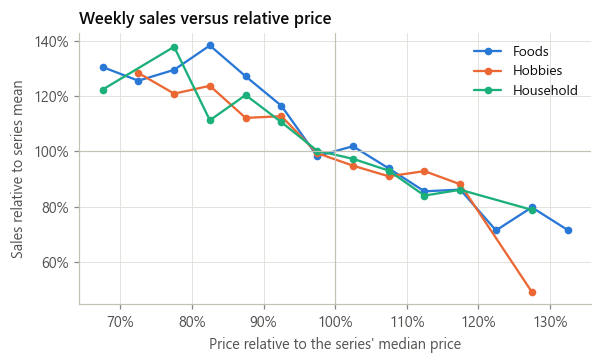

In [20]:
# Weekly sales per series (Walmart weeks run Saturday-Friday; incomplete weeks dropped)
week_ids = cal["wm_yr_wk"].to_numpy()
starts = np.r_[0, np.flatnonzero(np.diff(week_ids)) + 1]
full_week = np.diff(np.r_[starts, T]) == 7
weekly = np.add.reduceat(Y.astype(np.int32), starts, axis=1)[:, full_week]
weeks = week_ids[starts][full_week]

wk = pd.DataFrame({"row": np.repeat(np.arange(len(sales)), len(weeks)), "wm_yr_wk": np.tile(weeks, len(sales)),
                   "units": weekly.ravel()})
row_keys = sales[["item_id", "store_id"]].astype(str).reset_index(names="row")
pr = prices_train.astype({"item_id": str, "store_id": str}).merge(row_keys, on=["item_id", "store_id"])[["row", "wm_yr_wk", "sell_price"]]
wk = wk.merge(pr, on=["row", "wm_yr_wk"], how="inner")
first_sale_week = week_ids[stats.first_sale.fillna(T).astype(int).to_numpy() - 1]
wk = wk[wk.wm_yr_wk.to_numpy() >= first_sale_week[wk.row.to_numpy()]]  # active weeks only
wk["rel_units"] = wk.units / wk.groupby("row").units.transform("mean")
wk["rel_price"] = wk.sell_price / wk.groupby("row").sell_price.transform("median")
wk["cat_id"] = stats.cat_id.to_numpy()[wk.row]
wk = wk[np.isfinite(wk.rel_units)]

bins = np.arange(0.5, 1.5001, 0.05)
wk["bin"] = pd.cut(wk.rel_price, bins)
response = wk.groupby(["cat_id", "bin"], observed=True).agg(rel_units=("rel_units", "mean"), n=("rel_units", "size")).reset_index()
response["mid"] = response["bin"].apply(lambda b: b.mid).astype(float)
response = response[response.n >= 2000]
response.drop(columns="bin").to_csv(RESULTS / "price_response.csv", index=False)
print(f"Item-store-weeks used: {len(wk):,}")

fig, ax = plt.subplots(figsize=(6, 3.2))
for c in CATS:
    r = response[response.cat_id == c]
    ax.plot(r.mid, r.rel_units, marker="o", ms=4, color=CATEGORY_COLORS[c], label=c.title())
ax.axhline(1, color=AXIS, lw=0.8)
ax.axvline(1, color=AXIS, lw=0.8)
ax.xaxis.set_major_formatter(pct)
ax.yaxis.set_major_formatter(pct)
ax.grid(axis="x", visible=True)
ax.set_title("Weekly sales versus relative price")
ax.set_xlabel("Price relative to the series' median price")
ax.set_ylabel("Sales relative to series mean")
ax.legend(loc="upper right")
savefig(fig, "price_response")
plt.show()

## 9. Long zero runs: possible stock-outs and delistings

A long run of zeros inside the active period of an otherwise selling product is more likely a stock-out
or a temporary delisting than a lack of demand. M5 contains no stock information, so these runs cannot
be separated from true zero demand; this is a limitation for the interpretation of zero forecasts
(Section 5.4).

In [21]:
thresholds = [28, 56, 91, 182, 365]
zero_runs = pd.DataFrame(
    {
        "longest_zero_run_at_least": [(stats.longest_zero_run >= d).mean() for d in thresholds],
        "trailing_zeros_at_least": [(stats.trailing_zeros >= d).mean() for d in thresholds],
    },
    index=pd.Index(thresholds, name="days"),
)
zero_runs.to_csv(RESULTS / "zero_runs.csv")
zero_runs.style.format("{:.1%}")

,longest_zero_run_at_least,trailing_zeros_at_least
days,,
28,79.9%,5.2%
56,64.3%,3.3%
91,48.4%,1.2%
182,20.5%,0.5%
365,6.0%,0.1%


## 10. Save per-series statistics

In [22]:
series_stats = pd.concat([sales[["id", *m5.ID_COLS]].reset_index(drop=True), stats.drop(columns="cat_id")], axis=1)
series_stats.to_parquet(m5.PROCESSED_DIR / "series_stats_train.parquet", index=False)
print(f"Saved {len(series_stats):,} rows to data/processed/series_stats_train.parquet")
series_stats.head()

Saved 30,490 rows to data/processed/series_stats_train.parquet


,id,item_id,dept_id,cat_id,store_id,state_id,first_sale,n_active,n_nonzero,zero_share,adi,cv2,mean_size,longest_zero_run,trailing_zeros,first_price_day,sbc_class,units_last28,revenue_last28
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,902.000,1009,421,0.583,2.397,0.270,1.425,34,0,897,intermittent,27,224.940
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,144.000,1765,402,0.772,4.391,0.236,1.226,30,4,141,intermittent,2,7.940
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,"1,106.000",806,216,0.732,3.731,0.292,1.333,77,0,1100,intermittent,16,47.520
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,37.000,1872,1296,0.308,1.444,0.585,2.537,41,0,36,lumpy,51,236.640
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,113.000,1796,963,0.464,1.865,0.406,1.920,49,0,113,intermittent,38,109.440


In [23]:
key_numbers = pd.Series(
    {
        "Item-store series": f"{len(sales):,}",
        "Training days": f"{T:,}",
        "Zero cells, raw matrix": f"{(Y == 0).mean():.1%}",
        "Zero cells that are pre-introduction": f"{leading_zeros / (Y == 0).sum():.1%}",
        "Median zero share (active period)": f"{stats.zero_share.median():.1%}",
        "Series with >50% zero days": f"{(stats.zero_share > 0.5).mean():.1%}",
        "Intermittent or lumpy series": f"{stats.sbc_class.isin(['intermittent', 'lumpy']).mean():.1%}",
        "Smooth series": f"{(stats.sbc_class == 'smooth').mean():.1%}",
        "ACF lag 7, total": f"{acf_total[6]:.2f}",
        "ACF lag 7, item median": f"{q50[6]:.2f}",
        "Revenue share of top 20% series": f"{top(conc_rev, 0.2):.1%}",
        "Series with zero revenue in last 28 days": f"{zero_weight:.1%}",
        "Series with a zero run of 91+ days": f"{(stats.longest_zero_run >= 91).mean():.1%}",
    },
    name="value",
)
key_numbers.to_csv(RESULTS / "key_numbers.csv")
key_numbers.to_frame()

,value
Item-store series,"30,490"
Training days,"1,913"
"Zero cells, raw matrix",68.2%
Zero cells that are pre-introduction,31.1%
Median zero share (active period),63.3%
Series with >50% zero days,67.2%
Intermittent or lumpy series,90.8%
Smooth series,6.3%
"ACF lag 7, total",0.76
"ACF lag 7, item median",0.08


## Key findings

1. **Structure.** 30,490 item-store series (3,049 items × 10 stores in 3 states), 42,840 series across the
   12 hierarchy levels; 1,913 training days.
2. **Leading zeros must be removed.** 68.2% of all item-store-day cells are zero, but 31.1% of these zeros
   lie before a product's first sale (77.1% of series start after `d_1`). The first recorded price precedes
   the first sale by a median of 2 days, so price availability is a good marker of a product's introduction.
3. **Bottom-level demand is intermittent.** Within the active period the median series has no sale on
   63.3% of days, and 67.2% of series have more than half zero days. Foods are the least intermittent
   (median 54%), Hobbies the most (78%).
4. **SBC classes.** 72.7% intermittent, 18.2% lumpy, 6.3% smooth, 2.9% erratic: 90.8% of the series are
   intermittent or lumpy, the regime in which continuous-demand models such as ARIMA and exponential
   smoothing are poorly suited (Section 2.3) and the choice of loss function matters (Section 7.2).
5. **Intermittency disappears with aggregation.** No zero-sale days at levels 1–9; 14% at the item level,
   33% at item × state, 60% at item × store. The WRMSSE therefore mixes very different forecasting
   problems across levels (Section 7.4).
6. **Little signal per series, strong signal in aggregate.** Lag-7 autocorrelation is 0.76 for total sales
   but only 0.08 for the median item-store series: individual series are dominated by noise, which is the
   case for pooling them in one global model (Section 4.2).
7. **Calendar effects.** Saturday sales are 19–26% above the weekly mean, Tuesday–Thursday 10–15% below.
   SNAP days raise Foods sales by 10% (CA), 15% (TX) and 29% (WI) but other categories by only 1–3%, so
   SNAP features should be state-specific. Thanksgiving (−28%), New Year (−23%) and Labor Day (+28%) are
   the largest event effects; stores are closed on Christmas Day.
8. **Trend.** Mean daily sales grew from 2012 to 2015 by 45% (Hobbies), 40% (Household) and 4% (Foods),
   partly through new products. Tree models cannot extrapolate beyond the training range (Section 4.4),
   so features should be relative (lags, rolling means) rather than absolute levels or time indices.
9. **Concentration.** In the last 28 training days the top 20% of series account for 68% of units and 65%
   of revenue; 5.2% of series sold nothing and get zero WRMSSE weight at level 12.
10. **Prices matter.** 66–80% of series change price at least once. Weeks priced 5–10% below a series'
    median price sell 10–16% more than average, weeks 10–15% above sell 7–16% less, so relative-price
    features are informative.
11. **Long zero runs.** 48.4% of series have a run of at least 91 consecutive zero days inside their active
    period (20.5% at least 182 days). Without inventory data these cannot be told apart from true zero
    demand: stock-outs and temporary delistings are a limitation for interpreting zero forecasts
    (Sections 5.4 and 8.2).
